# 06 - Explanation Stability Under Input Noise (Stability module)

*Method designed by the teammate (Stability module); integrated into the shared pipeline so that it uses the same
data, saved models, SHAP/LIME configuration and one-hot aggregation as the Fairness module.*

**Question.** If a person's numeric features change very slightly, does the explanation stay the same?

**Method.** For sampled test instances, Gaussian noise of 1%, 5% and 10% of each numeric feature's training standard
deviation is added (one random draw shared by all levels, clipped to the training range). Original and perturbed
explanations are compared per instance with **Spearman rho**, **top-3 / top-5 overlap**; we also record whether the
model's decision flips and how much its probability moves. **0% noise** re-explains the same input and measures the
explainer's own randomness. Three seeds (42, 43, 44) repeat the experiment.

| Hypothesis | Test |
|---|---|
| **S-H1** SHAP and LIME are equally stable | Wilcoxon signed-rank (paired by instance), Holm |
| **S-H2** LR, RF and XGBoost are equally stable | Friedman + Kendall's W, pairwise Wilcoxon post-hoc, Holm |
| **S-H3** stability is the same for privileged and unprivileged groups | Mann-Whitney U, Holm |

In [1]:
# --- Setup: works both in Google Colab and locally ---------------------------
# Colab: choose ONE way to get the project:
#   (a) USE_DRIVE = True  -> upload the fairness-xai folder to "My Drive"
#   (b) REPO_URL = "..."  -> clone it from GitHub
# Locally (Jupyter / VS Code) nothing needs changing.
import importlib.metadata
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False
DRIVE_PROJECT = "/content/drive/MyDrive/fairness-xai"
REPO_URL = ""  # e.g. "https://github.com/<your-user>/fairness-xai.git"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    elif REPO_URL:
        PROJECT_ROOT = Path("/content/fairness-xai")
        if not PROJECT_ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
    else:
        raise RuntimeError("Set USE_DRIVE = True or REPO_URL so Colab can find the project.")
    # Install the pinned versions once. If Colab then asks to "Restart session",
    # click it and run this cell again - the install is skipped the second time.
    try:
        already = importlib.metadata.version("shap") == "0.48.0"
    except importlib.metadata.PackageNotFoundError:
        already = False
    if not already:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(PROJECT_ROOT / "requirements.txt")], check=True)
else:
    # Locally the notebook runs from notebooks/, so the project root is its parent.
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\tarun\Desktop\Mini Project\fairness-xai


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.explain import lime_values, make_lime_explainer, shap_values
from src.models import load_model, model_path, train_all
from src.preprocess import aggregate_by_original, map_transformed_to_original, prepare_dataset
from src.stability import (QUICK_STABILITY, STABILITY_SETTING, StabilitySettings, compare_rankings,
                           plot_stability_vs_noise, run_stability_all)

config.setup_logging()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# QUICK = True: 10 instances, 1 seed, results in results/quick/ (a few minutes on Colab).
# RECOMPUTE = False loads the tables written by `python -m src.run_all` if they exist.
QUICK = False
RECOMPUTE = False
if QUICK:
    config.set_results_dir(config.PROJECT_ROOT / "results" / "quick")

C:\Users\tarun\Desktop\Mini Project\fairness-xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Run (or load) the stability experiment

In [3]:
prepared = {}
for name in config.DATASETS:
    loaded, split = prepare_dataset(name, save=False)
    if not all(model_path(name, s, m).exists() for s in config.SETTINGS for m in config.MODEL_NAMES):
        train_all(split, loaded.metadata)
    prepared[name] = (loaded, split)

if RECOMPUTE or QUICK or not config.table_path("stability_raw.csv").exists():
    run_stability_all(prepared, QUICK_STABILITY if QUICK else StabilitySettings(),
                      config.QUICK_N_BOOTSTRAP if QUICK else config.N_BOOTSTRAP)

load = lambda f: pd.read_csv(config.table_path(f))
raw, summary = load("stability_raw.csv"), load("stability_summary.csv")
print(f"{len(raw):,} instance x level comparisons; seeds {sorted(int(s) for s in raw['seed'].unique())}; "
      f"skipped (constant attributions): {int(raw['rho'].isna().sum())}")

14:59:34 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


14:59:34 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


14:59:34 | INFO    | src.data | COMPAS ready: 5278 rows, 8 features, positive rate 0.470.


14,400 instance x level comparisons; seeds [42, 43, 44]; skipped (constant attributions): 0


## 2. Stability tables and figures

=== Adult Income: mean Spearman rho ===


noise                           0%      1%     10%      5%
model               method                                
logistic_regression lime    0.9676  0.9470  0.9447  0.9484
                    shap    1.0000  0.9969  0.9655  0.9833
random_forest       lime    0.9668  0.9489  0.9449  0.9464
                    shap    1.0000  0.9996  0.9860  0.9941
xgboost             lime    0.8811  0.8771  0.8780  0.8717
                    shap    1.0000  0.9597  0.9059  0.9285

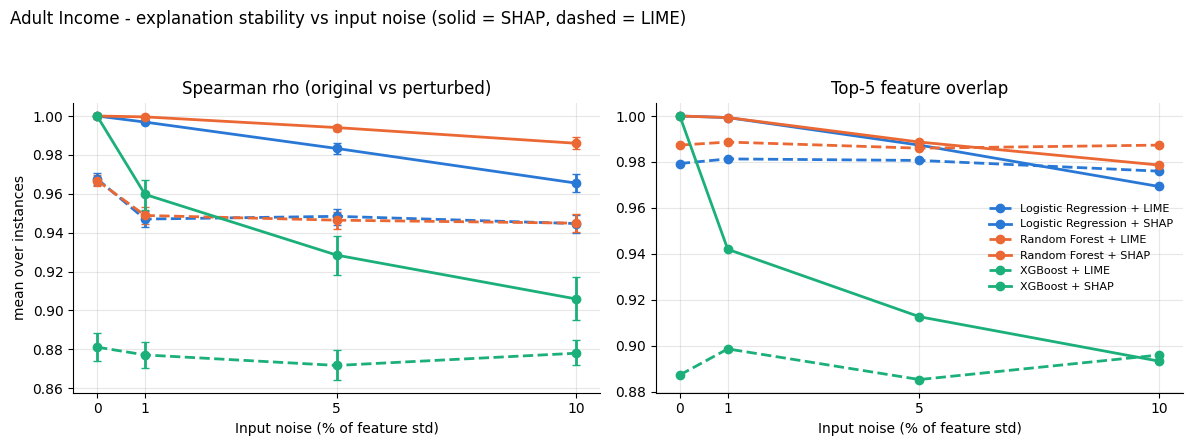

=== COMPAS: mean Spearman rho ===


noise                           0%      1%     10%      5%
model               method                                
logistic_regression lime    0.8151  0.7663  0.7581  0.7609
                    shap    1.0000  0.9985  0.9720  0.9915
random_forest       lime    0.8582  0.7483  0.7403  0.7484
                    shap    1.0000  0.9979  0.9024  0.9553
xgboost             lime    0.7297  0.6325  0.6388  0.6303
                    shap    1.0000  0.9266  0.8950  0.9224

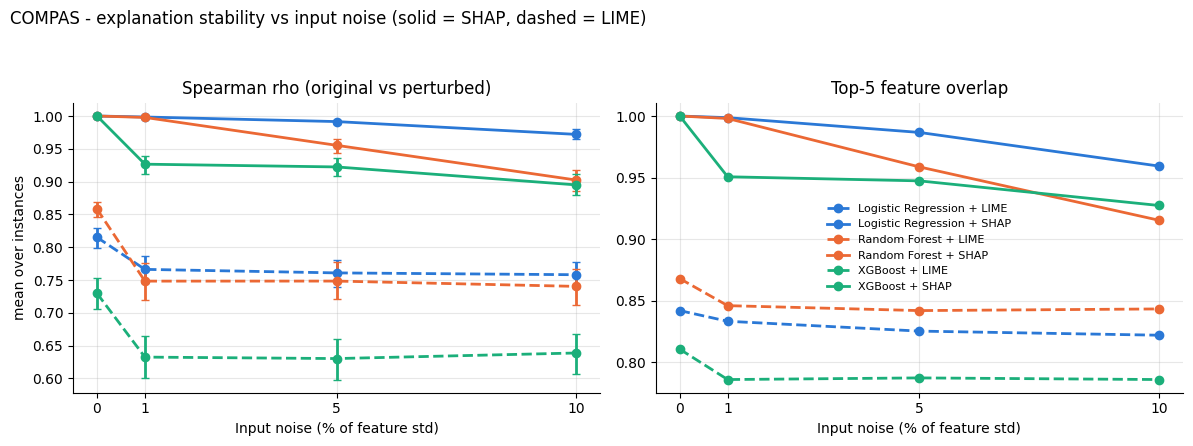

In [4]:
for dataset in config.DATASETS:
    part = summary[summary["dataset"] == dataset].copy()
    part["noise"] = (part["noise"] * 100).map(lambda v: f"{v:g}%")
    print(f"=== {config.DATASET_DISPLAY_NAMES[dataset]}: mean Spearman rho ===")
    display(part.pivot_table(index=["model", "method"], columns="noise", values="rho").round(4))
    display(plot_stability_vs_noise(summary, dataset))

In [5]:
display(summary[["dataset", "model", "method", "noise", "rho", "rho_ci_low", "rho_ci_high", "top5",
                 "pred_flip_rate", "mean_abs_dprob", "n_valid", "n_skipped"]].round(4))

,dataset,model,method,noise,rho,rho_ci_low,rho_ci_high,top5,pred_flip_rate,mean_abs_dprob,n_valid,n_skipped
0,adult,logistic_regression,lime,0.00,0.9676,0.9646,0.9707,0.9793,0.0000,0.0000,300,0
1,adult,logistic_regression,lime,0.01,0.9470,0.9427,0.9513,0.9813,0.0000,0.0015,300,0
2,adult,logistic_regression,lime,0.05,0.9484,0.9441,0.9524,0.9807,0.0133,0.0078,300,0
3,adult,logistic_regression,lime,0.10,0.9447,0.9399,0.9492,0.9760,0.0200,0.0158,300,0
4,adult,logistic_regression,shap,0.00,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,300,0
5,adult,logistic_regression,shap,0.01,0.9969,0.9963,0.9974,0.9993,0.0000,0.0015,300,0
6,adult,logistic_regression,shap,0.05,0.9833,0.9804,0.9862,0.9873,0.0133,0.0078,300,0
7,adult,logistic_regression,shap,0.10,0.9655,0.9611,0.9700,0.9693,0.0200,0.0158,300,0
8,adult,random_forest,lime,0.00,0.9668,0.9642,0.9697,0.9873,0.0000,0.0000,300,0
9,adult,random_forest,lime,0.01,0.9489,0.9444,0.9531,0.9887,0.0000,0.0002,300,0


**Reading the 0% column.** SHAP (Tree/Linear) is deterministic, so re-explaining the same input gives rho = 1.
LIME draws random samples, so even with *no* input change its ranking moves - part of LIME's "instability" at
1-10% noise is this sampling randomness, not the noise.

## 3. S-H1: SHAP vs LIME

In [6]:
tests_a = load("stability_test_shap_vs_lime.csv")
display(tests_a[["dataset", "model", "noise", "metric", "n", "shap_mean", "lime_mean", "p_value", "p_holm",
                 "reject_h0"]].round(4))
rejected = tests_a[tests_a["reject_h0"]]
print(f"H0 rejected in {len(rejected)} of {len(tests_a)} tests; in "
      f"{int((rejected['shap_mean'] > rejected['lime_mean']).sum())} of these SHAP is the more stable explainer.")

,dataset,model,noise,metric,n,shap_mean,lime_mean,p_value,p_holm,reject_h0
0,adult,logistic_regression,0.01,rho,300,0.9969,0.9470,0.0000,0.0000,True
1,adult,logistic_regression,0.05,rho,300,0.9833,0.9484,0.0000,0.0000,True
2,adult,logistic_regression,0.10,rho,300,0.9655,0.9447,0.0000,0.0000,True
3,adult,random_forest,0.01,rho,300,0.9996,0.9489,0.0000,0.0000,True
4,adult,random_forest,0.05,rho,300,0.9941,0.9464,0.0000,0.0000,True
5,adult,random_forest,0.10,rho,300,0.9860,0.9449,0.0000,0.0000,True
6,adult,xgboost,0.01,rho,300,0.9597,0.8771,0.0000,0.0000,True
7,adult,xgboost,0.05,rho,300,0.9285,0.8717,0.0000,0.0000,True
8,adult,xgboost,0.10,rho,300,0.9059,0.8780,0.0000,0.0000,True
9,compas,logistic_regression,0.01,rho,300,0.9985,0.7663,0.0000,0.0000,True


H0 rejected in 30 of 36 tests; in 30 of these SHAP is the more stable explainer.


## 4. S-H2: across models

In [7]:
tests_b, posthoc = load("stability_test_models.csv"), load("stability_posthoc.csv")
display(tests_b.round(4))
display(posthoc[posthoc["reject_h0"]].round(4))

,dataset,method,noise,metric,n,friedman_chi2,p_value,kendalls_w,p_holm,reject_h0
0,adult,lime,0.01,rho,300,243.9321,0.0,0.4066,0.0,True
1,adult,lime,0.05,rho,300,248.9265,0.0,0.4149,0.0,True
2,adult,lime,0.10,rho,300,197.5342,0.0,0.3292,0.0,True
3,adult,shap,0.01,rho,300,243.8883,0.0,0.4065,0.0,True
4,adult,shap,0.05,rho,300,198.7065,0.0,0.3312,0.0,True
5,adult,shap,0.10,rho,300,201.2105,0.0,0.3354,0.0,True
6,compas,lime,0.01,rho,300,83.2260,0.0,0.1387,0.0,True
7,compas,lime,0.05,rho,300,104.8611,0.0,0.1748,0.0,True
8,compas,lime,0.10,rho,300,71.5009,0.0,0.1192,0.0,True
9,compas,shap,0.01,rho,300,252.4683,0.0,0.4208,0.0,True


,dataset,method,noise,metric,pair,mean_diff,p_value,p_holm,reject_h0
1,adult,lime,0.01,rho,logistic_regression vs xgboost,0.0699,0.0000,0.0000,True
2,adult,lime,0.01,rho,random_forest vs xgboost,0.0717,0.0000,0.0000,True
4,adult,lime,0.05,rho,logistic_regression vs xgboost,0.0767,0.0000,0.0000,True
5,adult,lime,0.05,rho,random_forest vs xgboost,0.0747,0.0000,0.0000,True
7,adult,lime,0.10,rho,logistic_regression vs xgboost,0.0667,0.0000,0.0000,True
8,adult,lime,0.10,rho,random_forest vs xgboost,0.0669,0.0000,0.0000,True
9,adult,shap,0.01,rho,logistic_regression vs random_forest,-0.0027,0.0000,0.0000,True
10,adult,shap,0.01,rho,logistic_regression vs xgboost,0.0372,0.0000,0.0000,True
11,adult,shap,0.01,rho,random_forest vs xgboost,0.0399,0.0000,0.0000,True
12,adult,shap,0.05,rho,logistic_regression vs random_forest,-0.0107,0.0000,0.0000,True


## 5. S-H3: stability per demographic group (link to the Fairness module)

In [8]:
by_group = load("stability_by_group.csv")
display(by_group[["dataset", "model", "method", "attribute", "privileged", "unprivileged", "n_privileged",
                  "n_unprivileged", "rho_privileged", "rho_unprivileged", "p_value", "p_holm",
                  "rank_biserial", "reject_h0"]].round(4))

,dataset,model,method,attribute,privileged,unprivileged,n_privileged,n_unprivileged,rho_privileged,rho_unprivileged,p_value,p_holm,rank_biserial,reject_h0
0,adult,logistic_regression,lime,sex,Male,Female,199,101,0.9460,0.9480,0.7803,1.0000,-0.0198,False
1,adult,logistic_regression,shap,sex,Male,Female,199,101,0.9815,0.9826,0.3548,1.0000,-0.0653,False
2,adult,random_forest,lime,sex,Male,Female,199,101,0.9467,0.9468,0.9888,1.0000,0.0010,False
3,adult,random_forest,shap,sex,Male,Female,199,101,0.9927,0.9941,0.3047,1.0000,-0.0689,False
4,adult,xgboost,lime,sex,Male,Female,199,101,0.8740,0.8788,0.5340,1.0000,-0.0440,False
5,adult,xgboost,shap,sex,Male,Female,199,101,0.9339,0.9264,0.7800,1.0000,0.0198,False
6,adult,logistic_regression,lime,race,White,Non-White,262,38,0.9472,0.9433,0.4338,1.0000,0.0786,False
7,adult,logistic_regression,shap,race,White,Non-White,262,38,0.9815,0.9848,0.8028,1.0000,-0.0251,False
8,adult,random_forest,lime,race,White,Non-White,262,38,0.9483,0.9360,0.1518,1.0000,0.1439,False
9,adult,random_forest,shap,race,White,Non-White,262,38,0.9932,0.9932,0.3082,1.0000,0.0972,False


## 6. Accuracy vs stability (Pareto)
The original notebook combined AUC and stability into one "balance score". A weighted score hides the trade-off,
so - as in the Fairness module - we mark the Pareto-optimal rows instead.

In [9]:
display(load("stability_tradeoff.csv").round(4))

,dataset,model,method,stability_rho,stability_top5,pred_flip_rate,accuracy,roc_auc,is_pareto
0,adult,logistic_regression,lime,0.9467,0.9793,0.0111,0.8429,0.9026,False
1,adult,logistic_regression,shap,0.9819,0.9853,0.0111,0.8429,0.9026,False
2,adult,random_forest,lime,0.9467,0.9873,0.0044,0.8544,0.9147,False
3,adult,random_forest,shap,0.9932,0.9889,0.0044,0.8544,0.9147,True
4,adult,xgboost,lime,0.8756,0.8933,0.0756,0.8645,0.9261,False
5,adult,xgboost,shap,0.9313,0.9160,0.0756,0.8645,0.9261,True
6,compas,logistic_regression,lime,0.7617,0.8269,0.0189,0.6686,0.7208,False
7,compas,logistic_regression,shap,0.9873,0.9816,0.0189,0.6686,0.7208,True
8,compas,random_forest,lime,0.7457,0.8438,0.0244,0.6667,0.7155,False
9,compas,random_forest,shap,0.9519,0.9573,0.0244,0.6667,0.7155,False


## 7. Case study: one person, age + 1 year
XGBoost on Adult, the first test instance predicted >50K. We add one year to `age` and compare the top-4 features
of each explanation before and after.

In [10]:
loaded, split = prepared["adult"]
pipeline = load_model("adult", STABILITY_SETTING, "xgboost")
pre = pipeline.named_steps["preprocessor"]
names, mapping = list(pre.get_feature_names_out()), map_transformed_to_original(pre)

proba = pipeline.predict_proba(split.X_test)[:, 1]
row = split.X_test.iloc[[int(np.where(proba > 0.5)[0][0])]]
older = row.assign(age=row["age"] + 1)
lime_explainer = make_lime_explainer(pipeline, split.X_train, config.SEED)

explanations = {
    "SHAP": [aggregate_by_original(shap_values(pipeline, split.X_train, x), names, mapping).iloc[0] for x in (row, older)],
    "LIME": [aggregate_by_original(lime_values(pipeline, split.X_train, x, config.LIME_NUM_SAMPLES, config.SEED,
                                               explainer=lime_explainer)[0], names, mapping).iloc[0]
             for x in (row, older)],
}
print(f"Person: age {int(row['age'].iloc[0])} -> {int(older['age'].iloc[0])}; "
      f"P(>50K) {pipeline.predict_proba(row)[0, 1]:.3f} -> {pipeline.predict_proba(older)[0, 1]:.3f}")
for method, (before, after) in explanations.items():
    rho, top3, top5 = compare_rankings(before.to_numpy(), after.to_numpy())
    print(f"{method} top-4 before: {' -> '.join(before.nlargest(4).index)}")
    print(f"{method} top-4 after : {' -> '.join(after.nlargest(4).index)}")
    print(f"   Spearman {rho:.3f} | top-3 overlap {top3:.2f} | top-5 overlap {top5:.2f}")

Person: age 25 -> 26; P(>50K) 0.941 -> 0.951
SHAP top-4 before: capital-gain -> occupation -> marital-status -> relationship
SHAP top-4 after : capital-gain -> occupation -> marital-status -> relationship
   Spearman 1.000 | top-3 overlap 1.00 | top-5 overlap 1.00
LIME top-4 before: capital-gain -> native-country -> occupation -> workclass
LIME top-4 after : capital-gain -> native-country -> workclass -> occupation
   Spearman 0.853 | top-3 overlap 0.67 | top-5 overlap 1.00


## Summary
* Section 2 shows how quickly each model + explainer loses stability as noise grows, and LIME's 0%-noise baseline.
* S-H1 (section 3) and S-H2 (section 4) test whether the explainer and the model matter; S-H3 (section 5) asks
  whether explanations are less stable for one demographic group - the bridge to the Fairness module.
* Tree models split exactly at observed integer values (e.g. `age < 26`), so even 1% noise can cross a split:
  for trees the *direction* of the noise matters more than its size.